In [34]:
logs = ["user_1", "user_3", "user_1", "user_5", "user_3", "user_1"]
queries = ["user_1", "user_2", "user_3"]

In [35]:
def user_occurences(logs, queries):
  for user_id in queries:
    print(f"this user :{user_id} logged for {logs.count(user_id)}")

In [36]:
user_occurences(logs,queries)

this user :user_1 logged for 3
this user :user_2 logged for 0
this user :user_3 logged for 2


### Why the Brute-Force Approach Is Inefficient

> ⚠️ **Performance note**
>
> A brute-force solution loops through `queries` and scans `logs` for every query. This results in a time complexity of \(O(N 	imes Q)\), which can time out on HackerRank's hidden test cases.


### Better Approach: Count First, Query Second

Build a frequency dictionary by scanning `logs` once, then use a dictionary lookup for each query. This avoids repeatedly scanning the full log list and gives an average time complexity of \(O(N + Q)\).


In [37]:
def get_frequencies(logs, queries):
  frequency_map = {}
  for user_id in logs:
    frequency_map[user_id] =frequency_map.get(user_id,0)+1
  result = []

  for q in queries:
      result.append(frequency_map.get(q,0))
      print(f"this user :{q} logged for {frequency_map.get(q,0)}")


In [38]:
get_frequencies(logs,queries)

this user :user_1 logged for 3
this user :user_2 logged for 0
this user :user_3 logged for 2


In [39]:
def stack(str_input):
  list_str = []
  for char in str_input:
    if char == "{" or char == "[" or char == "(":
      list_str.append(char)
    elif char == "}" or char == "]" or char == ")":
      if list_str.pop() == char:
        continue
  if not list_str:
    return True
  else:
    return False



In [40]:
stack("{kgkjhdsf[lhsf(3135)]}")

True

### Key Fix: Match Opening and Closing Brackets

An opening bracket such as `{` will never equal its closing pair, `}`. Comparing them directly with `==` will always return `False`.

Use a dictionary to map each opening bracket to its corresponding closing bracket, then compare against the expected pair.


In [41]:
def is_balenced(str_input):
  list_str = []
  matching_pairs = {'(':')','{':'}','[':']'}
  for char in str_input:
    if char in matching_pairs.keys():
      list_str.append(char)
    elif char in matching_pairs.values():
      if list_str.pop() == char:
        continue
  if not list_str:
    return True
  else:
    return False

In [42]:
is_balenced("{kgkjhdsf[lhsf(3135)]")

False

#### Complexity Analysis

- **Time:** \(O(N)\) — the algorithm traverses the string of length \(N\) once.
- **Space:** \(O(N)\) — in the worst case (for example, `"[[[{{{"`), the stack can store up to \(N\) opening brackets.


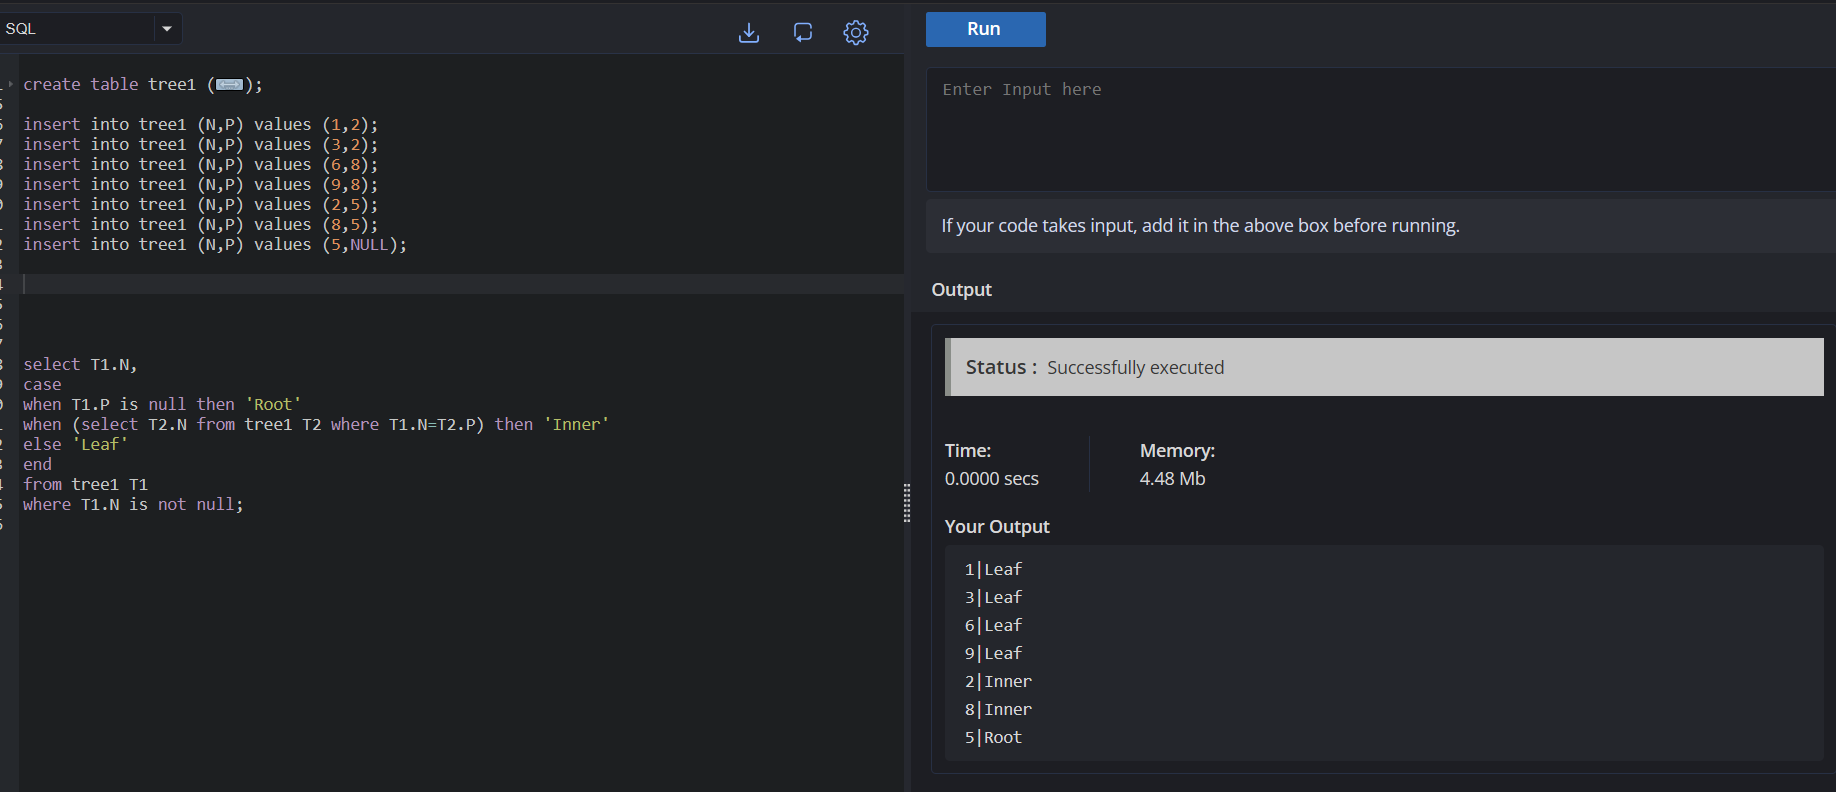

In [43]:
class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val = val
        self.left = left
        self.right = right

def classify_node(node, is_root=False):
  if not node:
    return None

  has_children = (node.left is not None) or (node.right is not None)

  if is_root:
    return "Root"

  if not has_children:
    return "Leaf"

  return "Inner"

In [44]:
leaf1 = TreeNode(1)
leaf6 = TreeNode(6)
leaf9 = TreeNode(9)

inner_node_2 = TreeNode(2, left=leaf1)
inner_node_8 = TreeNode(8, left=leaf6, right=leaf9)

root_node_5 = TreeNode(5, left=inner_node_2, right=inner_node_8)

# Testing classification
print(f"Node 5: {classify_node(root_node_5, is_root=True)}")  # Output: Root
print(f"Node 8: {classify_node(inner_node_8, is_root=False)}") # Output: Inner
print(f"Node 1: {classify_node(leaf1, is_root=False)}")        # Output: Leaf

Node 5: Root
Node 8: Inner
Node 1: Leaf


### Alternative Input Format: Node–Parent Pairs

This approach uses a raw list of \((N, P)\) pairs, where each pair represents a **Node** and its **Parent**. This is similar to a database table and does not require a `TreeNode` class.


In [45]:
def classify_nodes_from_pairs(pairs):
  parents = set()
  all_nodes = set()
  parent_map = {}


  for node, parent in pairs:
    all_nodes.add(node)
    parent_map[node] = parent
    if parent is not None:
      parents.add(parent)

  classifications = {}
  for node in sorted(all_nodes):
    parent = parent_map[node]

    if parent is None:
      classifications[node] = "Root"
    elif node in parents:
      classifications[node] = "Inner"
    else:
      classifications[node] = "Leaf"

  return classifications

In [46]:
data = [(1, 2), (3, 2), (6, 8), (9, 8), (2, 5), (8, 5), (5, None)]
print(classify_nodes_from_pairs(data))

{1: 'Leaf', 2: 'Inner', 3: 'Leaf', 5: 'Root', 6: 'Leaf', 8: 'Inner', 9: 'Leaf'}


[(5, 2), (5, 8), (2, 1), (2, 3), (8, 6), (8, 9)]


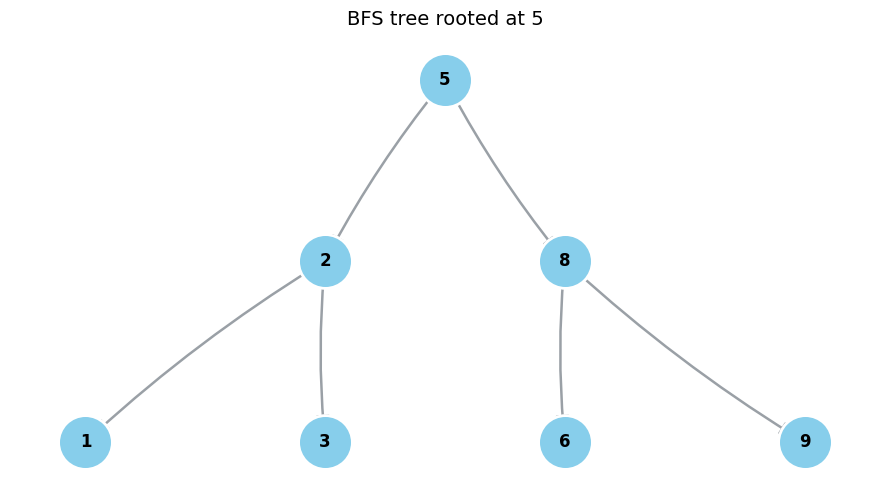

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

G = nx.Graph(name="Test_BST")
G.add_nodes_from([1, 2, 3, 5, 6, 8, 9])
G.add_edges_from([(1, 2), (3, 2), (6, 8), (9, 8), (2, 5), (8, 5)])

T = nx.bfs_tree(G, source=5)
print(list(T.edges()))  # [(5, 2), (5, 8), (2, 1), (2, 3), (8, 6), (8, 9)]

# Try Graphviz-based hierarchical layout first, fallback to pure-Python BFS layout
try:
    pos = nx.nx_agraph.graphviz_layout(T, prog='dot')
except Exception:
    try:
        pos = nx.nx_agraph.graphviz_layout(T, prog='dot')
    except Exception:
        def bfs_tree_layout(T, root, layer_gap=1.5, node_gap=1.5):
            layers = {}
            visited = {root}
            q = deque([(root, 0)])
            while q:
                node, depth = q.popleft()
                layers.setdefault(depth, []).append(node)
                for w in T[node]:
                    if w not in visited:
                        visited.add(w)
                        q.append((w, depth + 1))
            pos = {}
            for depth, nodes in layers.items():
                n = len(nodes)
                xs = [i - (n - 1) / 2 for i in range(n)]
                for i, node in enumerate(nodes):
                    pos[node] = (xs[i] * node_gap, -depth * layer_gap)
            return pos
        pos = bfs_tree_layout(T, 5)

fig, ax = plt.subplots(figsize=(9, 5))

nx.draw_networkx_edges(
    T, pos, ax=ax,
    arrows=True, arrowstyle='-|>', arrowsize=20,
    edge_color='#9aa0a6', width=1.8,
    connectionstyle='arc3,rad=0.05',
    min_source_margin=0.1, min_target_margin=0.1,
)

nx.draw_networkx_nodes(
    T, pos, ax=ax,
    node_color='skyblue', edgecolors='white',
    linewidths=2, node_size=1500,
)

nx.draw_networkx_labels(T, pos, ax=ax, font_size=12, font_weight='bold')

ax.set_title('BFS tree rooted at 5', fontsize=14, pad=12)
ax.axis('off')
plt.tight_layout()
plt.show()

#### Complexity and Database Connection

- **Lookup:** \(O(1)\) per node when using tree pointers.
- **Sorted output:** \(O(N \log N)\) if node values must be sorted.

**Database mapping:** A B-tree index navigates from the root through internal nodes and finally to leaf nodes, where the actual row pointers (ROWIDs) reside.


In [48]:
arr = [2, 11, 7, 15] # we start from index 0 the return should be as following [0,2]
target = 9   # What are les valeurs if you sum up gives target for exemple 2+7=9=target he want the index of the value on the array means [0,2]

In [49]:
print(range(0,len(arr)-1))

range(0, 3)


In [50]:
for value1 in range(0,len(arr)-1):
  for value2 in range(value1+1,len(arr)-1):
    if arr[value1] + arr[value2] == target:
      print(f"[{value1},{value2}]")

[0,2]


### Optimizing Two Sum

There are two primary ways to improve on the \(O(N^2)\) brute-force solution that uses a double loop.


In [51]:
def two_sum_hashmap(arr, target):
  seen = {}           # {"7":2}
  for i, num in enumerate(arr):
    print(seen)
    complement = target - num
    if complement in seen:
      return [seen[complement],i]
    seen[num] = i
  return []

In [52]:
two_sum_hashmap(arr,target)

{}
{2: 0}
{2: 0, 11: 1}


[0, 2]

#### Approach 1: Hash Map — \(O(N)\) Time, \(O(N)\) Space

Keep track of the numbers already seen and their indices in a dictionary, using the structure `seen = {number: index}`.

1. For each number `num` at index `i`, calculate its complement: `target - num`.
2. Check whether that complement is already in `seen`. A dictionary lookup takes average \(O(1)\) time.
3. If it exists, return the stored index and the current index. Otherwise, store `seen[num] = i` and continue.


In [53]:
""" [1,2,3,4,5,6]   (5)<-516543  (4)<-5543 (3)<-16543 (2)<-514<------ left_pointer  target=5
                           |          |         |         |
                           |          |         |         |
    right_pointer   ------>|<---------|<--------|<--------|"""

' [1,2,3,4,5,6]   (5)<-516543  (4)<-5543 (3)<-16543 (2)<-514<------ left_pointer  target=5\n                           |          |         |         |\n                           |          |         |         |\n    right_pointer   ------>|<---------|<--------|<--------|'

In [54]:
def two_sum_two_pointers(arr, target):
  left = 0
  right = len(arr) - 1

  while left < right:
    current_sum = arr[left] + arr[right]
    if current_sum == target:
      return [left,right]
    elif current_sum < target:
      left += 1
    else:
      right -= 1
  return []

In [55]:
arr = [2, 11, 15, 7]
target = 9
print("Sorted array result :",two_sum_two_pointers(sorted(arr),target))
print("Unsorted array result :",two_sum_two_pointers(arr,target))

Sorted array result : [0, 1]
Unsorted array result : [0, 3]


#### Approach 2: Two Pointers — \(O(N \log N)\), or \(O(N)\) if Already Sorted

When the array is sorted, you can avoid extra hash-map memory by starting one pointer at each end:

- `left = 0` — the first element.
- `right = len(arr) - 1` — the last element.

Compare `arr[left] + arr[right]` with the target. Move `left` rightward if the sum is too small; move `right` leftward if the sum is too large. If sorting is required first, the total time complexity is \(O(N \log N)\); otherwise, the scan is \(O(N)\).


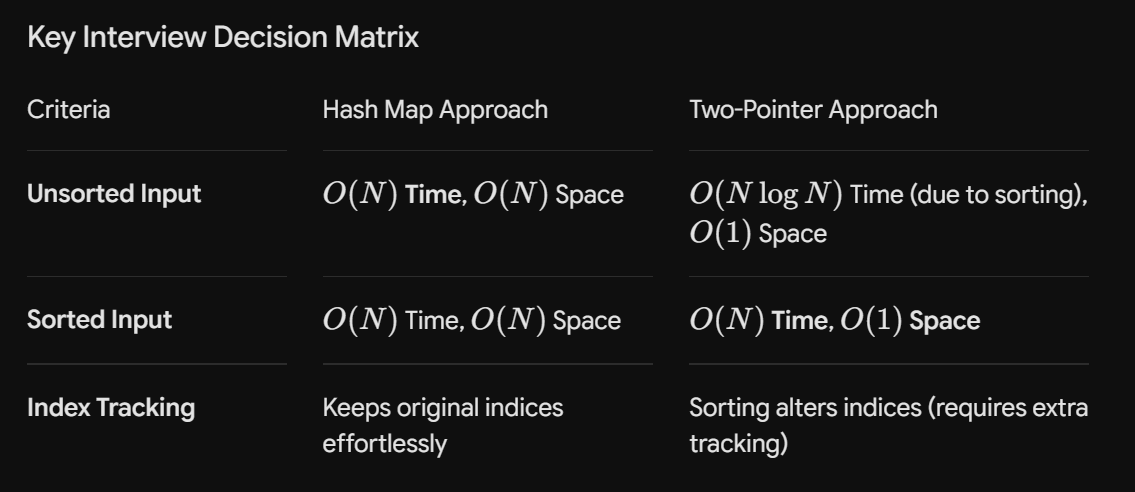

In [56]:
class ListNode:
    def __init__(self, x):
        self.val = x
        self.next = None

def has_cycle_hashset(head):
    visited_nodes = set()
    current = head

    while current is not None:
        # If the memory reference of the current node is already in the set, a cycle exists
        if current in visited_nodes:
            return True
        
        # Mark this node object as seen
        visited_nodes.add(current)
        
        # Move to the next node
        current = current.next

    # Reached the end of the list (None) -> No cycle
    return False

In [57]:
node1 = ListNode(1)
node2 = ListNode(2)
node3 = ListNode(3)

head = node1
node1.next = node2
node2.next = node1

has_cycle_hashset(head)

True

## Linked List Cycle Detection

### Approach 1: Hash Set — \(O(N)\) Extra Space

Maintain a set of visited node references while traversing the linked list. If a node is encountered for a second time, a cycle exists.

- **Time:** \(O(N)\), because each node is checked as it is visited.
- **Space:** \(O(N)\), because the set may store every visited node.


In [58]:
class ListNode:
  def __init__(self, value):
    self.value = value
    self.next = None



def has_cycle_SlowFast(head):

  if not head or not head.next:
    return False

  slow = head
  fast = head

  while fast and fast.next:
    slow = slow.next
    fast = fast.next.next

    if slow == fast:
      return True

  return False

In [59]:
head = node(1)
head.next = node(2)
node1 = head.next
head.next.next = node(3)
node2 = head.next.next
head.next.next.next = node2


cycle_test(head)

True

### Approach 2: Fast and Slow Pointers — \(O(1)\) Auxiliary Space

This method is also known as **Floyd's Tortoise and Hare algorithm**.

1. Initialize two pointers at the head of the linked list: `slow` and `fast`.
2. Move `slow` one step at a time: `slow = slow.next`.
3. Move `fast` two steps at a time: `fast = fast.next.next`.

**Why it works:** If there is no cycle, `fast` eventually reaches `None`. If a cycle exists, `fast` enters the loop and eventually meets `slow` at the same node (`slow == fast`).


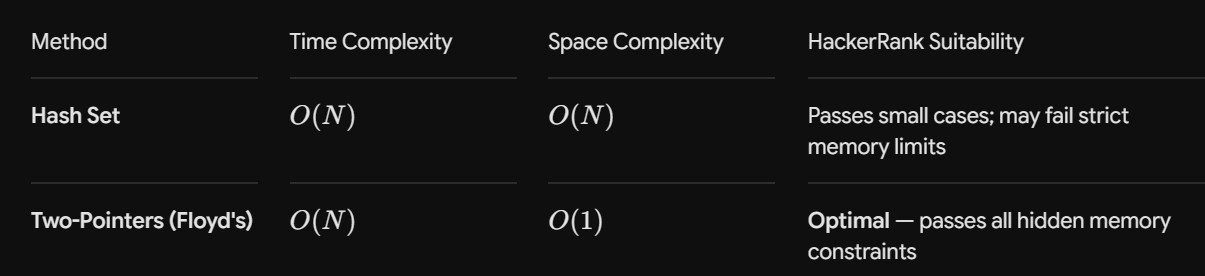

## Finding the Kth Largest Element with Heaps

### The Scenario

Imagine you have a massive array of database transaction amounts, `arr`, and need to find the \(K^{	ext{th}}\) largest transaction.


In [60]:
arr = [3, 2, 1, 5, 6, 4]
k = 2

**Expected output:** `5`

The sorted order is `[6, 5, 4, 3, 2, 1]`, so the 2nd largest element is `5`.


### Baseline Solution: Sort the Entire Array

```python
arr.sort(reverse=True)
return arr[k-1]
```


- **Time complexity:** \(O(N \log N)\), due to sorting.

> ⚠️ **Limitation**
>
> If an array contains 10 million rows and you only need the top 3 items, sorting the entire array wastes CPU time and memory.


### Optimized Solution: Keep a Min-Heap of Size \(K\)

A **min-heap** is a binary tree in which every parent is smaller than or equal to its children. Python's `heapq` module lets us use a regular list as a min-heap.

#### The “Bouncer” Strategy

Think of the heap as a VIP club that can hold exactly \(K\) people:

1. Push each element into the heap.
2. The smallest element is always at the front (index `0`).
3. Whenever the heap grows to size \(K + 1\), remove the smallest element.
4. By the end, the heap contains the \(K\) largest elements. Its root is the \(K^{	ext{th}}\) largest value.


In [64]:
import heapq

def find_kth_largest(arr, k):
    min_heap = []
    for num in arr:
        heapq.heappush(min_heap, num)
        if len(min_heap) > k:
            heapq.heappop(min_heap)
    return min_heap[0]  # The root of the min-heap is the kth largest element

In [65]:
k = 2
find_kth_largest(arr, k)

5

In [75]:
def find_kth_smallest(arr, k):
    max_heap = []
    for num in arr:
        heapq.heappush(max_heap, -num)
        if len(max_heap) > k:
            heapq.heappop(max_heap)
    return -max_heap[0]  # The root of the max-heap is the kth smallest element

In [76]:
k = 2
find_kth_smallest(arr, k)

2

#### Complexity Analysis

- **Time:** \(O(N \log K)\) — each of the \(N\) elements may trigger a push or pop, each costing \(O(\log K)\) while the heap stays around size \(K\). This is much faster than \(O(N \log N)\) when \(K\) is small relative to \(N\).
- **Space:** \(O(K)\) — only \(K\) elements are stored at a time, making this approach memory-efficient for data-engineering streams.


## String Searching with Tries (Prefix Trees)

In database systems, B-trees are useful for ordered values, but variable-length strings bring different challenges. **Tries** are tree structures used for prefix matching, autocomplete, and applications such as IP-address routing or searches like `SQL LIKE 'auto%'`.

### The Concept

A trie represents a word as a path through a tree, with each step corresponding to one character. Rather than storing an entire word in one node, the structure shares common prefixes between words.

Characters are used as keys in a dictionary that points to child nodes. A Boolean flag, `is_end_of_word`, marks the end of a complete word.


### Step-by-Step Dry Run

Let's insert two words: **CAT** and **CAR**.

#### Insert “CAT”

1. Start at the empty root.
2. `C` does not exist, so create a node for `C` and move to it.
3. `A` does not exist under `C`, so create a node for `A` and move to it.
4. `T` does not exist under `A`, so create a node for `T` and move to it.
5. Mark the node after `T` with `is_end_of_word = True`.

#### Insert “CAR”

1. Start at the root.
2. `C` already exists, so reuse it.
3. `A` already exists under `C`, so reuse it as well. Sharing the prefix saves memory.
4. `R` does not exist under `A`, so create a node for `R`.
5. Mark the node after `R` with `is_end_of_word = True`.


In [78]:
class TieNode:
    def __init__(self):
        self.children = {}
        self.is_end_of_word = False

class Trie:
    def __init__(self):
        self.root = TieNode()

    def insert(self, word):
        node = self.root
        for char in word:
            if char not in node.children:
                node.children[char] = TieNode()
            node = node.children[char]
        node.is_end_of_word = True


    def search (self, word):
        node = self.root
        for char in word:
            if char not in node.children:
                return False
            node = node.children[char]
        return node.is_end_of_word


    def starts_with(self , prefix):
        node = self.root
        for char in prefix:
            if char not in node.children:
                return False
            node = node.children[char]
        return True

In [82]:
trie1 = Trie()
trie1.insert("Car")
trie1.insert("Card")
trie1.insert("Care")
trie1.insert("Cat")

trie1.search("Car")  # True

trie1.starts_with("Ca")  # True

True

#### Complexity Analysis

- **Time:** \(O(L)\) for insertion and search, where \(L\) is the word length. A 5-letter word requires at most five character steps, regardless of whether the trie stores 10 words or 10 million words.
- **Space:** \(O(N 	imes L)\) in the worst case, when words share no prefixes. In real text, shared roots such as `auto`, `automobile`, and `automatic` can reduce the space required.


In [102]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_trie(trie):
    G = nx.DiGraph()
    labels = {}

    counter = [0]

    def add_node(node, prefix=""):
        node_id = counter[0]
        counter[0] += 1

        label = prefix if prefix else "root"
        if getattr(node, "is_end", False):
            label += "*"

        G.add_node(node_id)
        labels[node_id] = label

        children = getattr(node, "children", {})
        for char, child in children.items():
            child_id = add_node(child, prefix + char)
            G.add_edge(node_id, child_id)

        return node_id

    add_node(trie.root)

    pos = nx.spring_layout(G)
    plt.figure(figsize=(10, 6))
    nx.draw(
        G,
        pos,
        with_labels=False,
        node_color="skyblue",
        node_size=1800,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=18,
        edge_color="#888",
    )
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=10, font_weight="bold")
    plt.title("Trie visualization")
    plt.axis("off")
    plt.show()

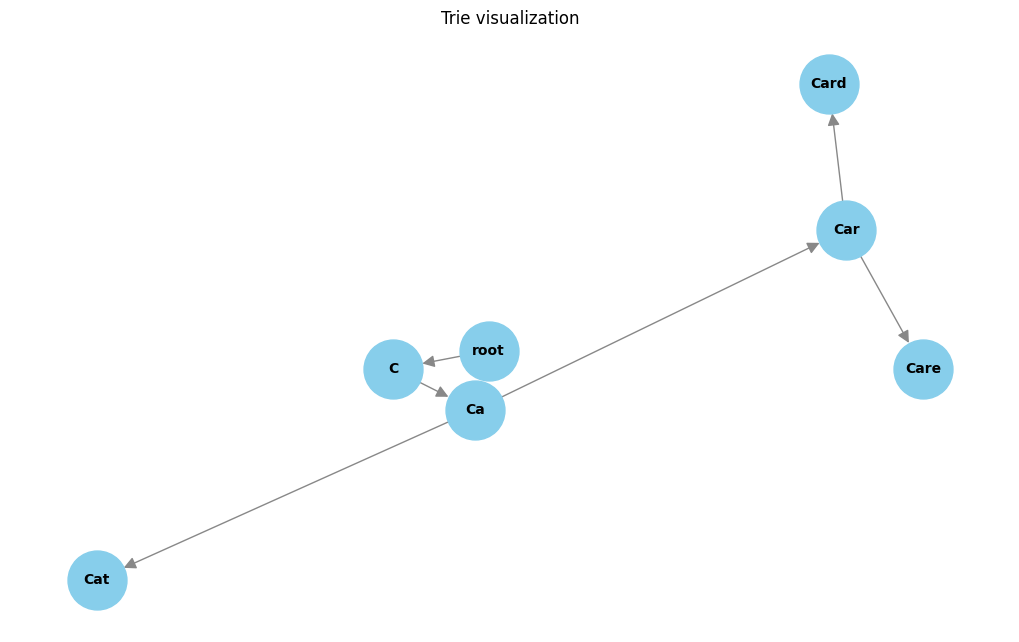

In [103]:
plot_trie(trie1)

## Graph Traversal: BFS and DFS

In database engineering, graphs model relationships and dependencies. Query execution plans may be represented as directed acyclic graphs (DAGs), while graph cycle detection can help identify deadlocks in transaction dependencies.


### 1. Representing a Graph with an Adjacency List

Before traversing a graph, represent it in code. A common, efficient Python representation is an **adjacency list**: a dictionary whose keys are nodes and whose values are lists of neighboring nodes.

For example, imagine this network of database servers:

- **Server 1** connects to servers 2 and 3.
- **Server 2** connects to server 4.
- **Server 3** connects to server 5.
- **Servers 4 and 5** have no outgoing connections.


In [104]:
# The Adjacency List Representation
graph = {
    1: [2, 3],
    2: [4],
    3: [5],
    4: [],
    5: []
}

Two standard graph traversal algorithms are **Breadth-First Search (BFS)** and **Depth-First Search (DFS)**. They differ in the order in which they explore neighboring nodes.


### 2. Breadth-First Search (BFS)

BFS explores a graph **level by level**, visiting immediate neighbors before moving deeper. It is useful for finding the shortest path in an unweighted graph.

- **Data structure:** A queue (first in, first out — FIFO).

#### Dry Run

1. Start at node `1`. Queue: `[1]`.
2. Remove `1`; add neighbors `2` and `3`. Queue: `[2, 3]`. Visited: `1`.
3. Remove `2`; add neighbor `4`. Queue: `[3, 4]`. Visited: `1, 2`.
4. Remove `3`; add neighbor `5`. Queue: `[4, 5]`. Visited: `1, 2, 3`.
5. Remove `4` and then `5`; neither has additional neighbors.

**Final traversal order:** `1 → 2 → 3 → 4 → 5`


In [106]:
from collections import deque


def bfs(graph, start_node):
    visited = set()
    queue = deque([start_node])
    visited.add(start_node)

    result = []

    while queue:

        current = queue.popleft()
        result.append(current)


        for neighbor in graph.get(current, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

    return result

In [107]:
bfs_result = bfs(graph, 1)
print("BFS Traversal Result:", bfs_result)  # Output: BFS Traversal Result

BFS Traversal Result: [1, 2, 3, 4, 5]


### 3. Depth-First Search (DFS)

DFS explores one branch as deeply as possible before backtracking. It is useful for exploring connectivity, traversing mazes, and detecting cycles such as dependency deadlocks.

- **Data structure:** A stack (last in, first out — LIFO). Recursive DFS uses Python's call stack.


#### Dry Run

1. Start at node `1` and follow its first neighbor to `2`.
2. From `2`, follow its first neighbor to `4`.
3. Node `4` has no neighbors, so backtrack to `1`.
4. From `1`, follow the next neighbor to `3`.
5. From `3`, follow its first neighbor to `5`.

**Final traversal order:** `1 → 2 → 4 → 3 → 5`


In [108]:
def dfs(graph, start_node, visited=None, result=None):
    if visited is None:
        visited = set()
    if result is None:
        result = []

    visited.add(start_node)
    result.append(start_node)

    for neighbor in graph.get(start_node, []):
        if neighbor not in visited:
            dfs(graph, neighbor, visited, result)

    return result

In [109]:
dfs_result = dfs(graph, 1)
print("DFS Traversal Result:", dfs_result)  # Output: DFS Traversal Result

DFS Traversal Result: [1, 2, 4, 3, 5]


#### Complexity Analysis

- **Time:** \(O(V + E)\) for both BFS and DFS, where \(V\) is the number of vertices (nodes) and \(E\) is the number of edges (connections). Each node and edge is considered at most a constant number of times.
- **Space:** \(O(V)\) for the visited set and the queue (BFS) or call stack (recursive DFS).
